<a href="https://colab.research.google.com/github/vaniararaandini03/Tugas-Probabilitas-dan-Distribusi-Probabilitas---Python/blob/main/TugasPython_Vania3TIE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

n(S) = 8 | n(K) = 3
Kejadian : ['AGG', 'GAG', 'GGA']
P(tepat 2 gambar) = 3/8 = 0.375
P(tepat 2 gambar) simulasi = 0.3723


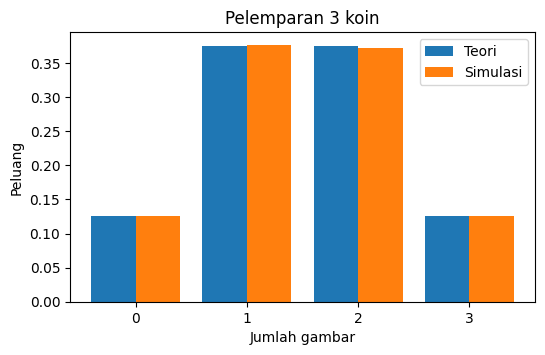

In [5]:
import itertools
from fractions import Fraction
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng()

# Ruang sampel 3 koin: A = Angka, G = Gambar
ruang = list(itertools.product(["A", "G"], repeat=3))
kejadian = [s for s in ruang if s.count("G") == 2]

p_teori = Fraction(len(kejadian), len(ruang))
print("n(S) =", len(ruang), "| n(K) =", len(kejadian))
print("Kejadian :", ["".join(s) for s in kejadian])
print("P(tepat 2 gambar) =", p_teori, "=", float(p_teori))

# Simulasi 100.000 kali lempar 3 koin (1 = gambar)
N = 100_000
jumlah_gambar = rng.integers(0, 2, size=(N, 3)).sum(axis=1)
p_sim = np.mean(jumlah_gambar == 2)
print("P(tepat 2 gambar) simulasi =", round(p_sim, 4))

# Grafik: teori vs simulasi
k = np.arange(4)
teori = stats.binom(3, 0.5).pmf(k)
sim = np.bincount(jumlah_gambar, minlength=4) / N
plt.figure(figsize=(6, 3.5))
plt.bar(k - 0.2, teori, width=0.4, label="Teori")
plt.bar(k + 0.2, sim, width=0.4, label="Simulasi")
plt.xticks(k); plt.xlabel("Jumlah gambar"); plt.ylabel("Peluang")
plt.title("Pelemparan 3 koin"); plt.legend(); plt.show()

P(King) = 1/13 | P(Hati) = 1/4 | P(King dan Hati) = 1/52
P(King atau Hati) = 4/13 = 0.3077
Cek langsung dari himpunan gabungan: 4/13
Simulasi = 0.3081


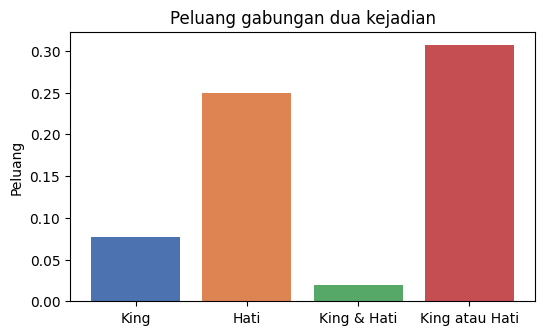

In [4]:
import itertools
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

bentuk = ["Hati", "Wajik", "Keriting", "Sekop"]
nilai = ["A"] + [str(i) for i in range(2, 11)] + ["J", "Q", "K"]
dek = list(itertools.product(nilai, bentuk))                   # 13 x 4 = 52 kartu

A = {kartu for kartu in dek if kartu[0] == "K"}               # kartu King
B = {kartu for kartu in dek if kartu[1] == "Hati"}            # kartu Hati

pA, pB = Fraction(len(A), 52), Fraction(len(B), 52)
pAB = Fraction(len(A & B), 52)
p_gabungan = pA + pB - pAB                                     # inklusi-eksklusi
print("P(King) =", pA, "| P(Hati) =", pB, "| P(King dan Hati) =", pAB)
print("P(King atau Hati) =", p_gabungan, "=", round(float(p_gabungan), 4))
print("Cek langsung dari himpunan gabungan:", Fraction(len(A | B), 52))

# Simulasi: ambil 1 kartu acak sebanyak 200.000 kali
idx = rng.integers(0, 52, size=200_000)
terambil = [dek[i] for i in idx]
p_sim = np.mean([(k[0] == "K") or (k[1] == "Hati") for k in terambil])
print("Simulasi =", round(p_sim, 4))

label = ["King", "Hati", "King & Hati", "King atau Hati"]
nilai_p = [float(pA), float(pB), float(pAB), float(p_gabungan)]
plt.figure(figsize=(6, 3.5))
plt.bar(label, nilai_p, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
plt.ylabel("Peluang"); plt.title("Peluang gabungan dua kejadian"); plt.show()

P(semua server mati)       = 0.001
P(minimal 1 server hidup) = 0.999
P(ketiganya hidup)        = 0.684
Simulasi P(minimal 1 hidup) = 0.999


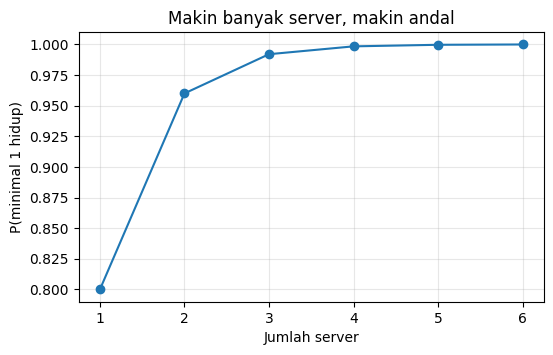

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

p_up = np.array([0.90, 0.95, 0.80])        # peluang tiap server hidup (saling bebas)

p_semua_mati = np.prod(1 - p_up)           # komplemen tiap server dikalikan
p_min_satu_hidup = 1 - p_semua_mati        # komplemen dari "semua mati"
p_semua_hidup = np.prod(p_up)
print("P(semua server mati)       =", round(p_semua_mati, 6))
print("P(minimal 1 server hidup) =", round(p_min_satu_hidup, 6))
print("P(ketiganya hidup)        =", round(p_semua_hidup, 6))

N = 200_000
hidup = rng.random((N, 3)) < p_up
p_sim = hidup.any(axis=1).mean()
print("Simulasi P(minimal 1 hidup) =", round(p_sim, 4))

# Grafik: kalau tiap server hanya 0,80, apa efek menambah jumlah server?
jumlah = np.arange(1, 7)
plt.figure(figsize=(6, 3.5))
plt.plot(jumlah, 1 - (1 - 0.8) ** jumlah, "o-")
plt.xlabel("Jumlah server"); plt.ylabel("P(minimal 1 hidup)")
plt.title("Makin banyak server, makin andal"); plt.grid(alpha=0.3); plt.show()

Jumlah OTP 6 digit: 1000000 | P(tebakan benar) = 1e-06
Jumlah password: 62990928000
Jumlah tim: 220 | tim tanpa senior: 56
P(minimal 1 senior) = 0.7455
Simulasi = 0.7422


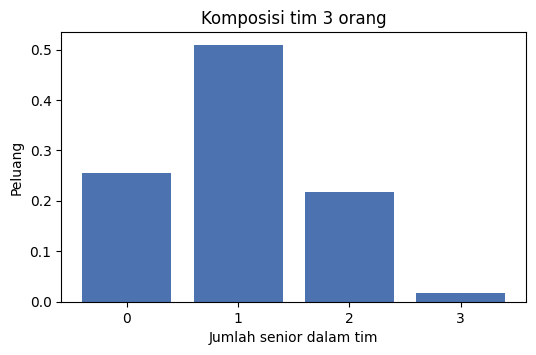

In [7]:
import math
import random
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# 1) OTP 6 digit (angka boleh berulang -> 10^6)
total_otp = 10 ** 6
print("Jumlah OTP 6 digit:", total_otp, "| P(tebakan benar) =", 1 / total_otp)

# 2) Password 8 huruf kecil tanpa huruf berulang (urutan penting -> permutasi)
print("Jumlah password:", math.perm(26, 8))

# 3) Tim 3 orang dari 12 programmer (4 senior, 8 junior) -> kombinasi
total_tim = math.comb(12, 3)
tanpa_senior = math.comb(8, 3)
p_min1_senior = 1 - tanpa_senior / total_tim
print("Jumlah tim:", total_tim, "| tim tanpa senior:", tanpa_senior)
print("P(minimal 1 senior) =", round(p_min1_senior, 4))

# Simulasi memilih tim secara acak
N = 100_000
programmer = ["S"] * 4 + ["J"] * 8
p_sim = sum("S" in random.sample(programmer, 3) for _ in range(N)) / N
print("Simulasi =", round(p_sim, 4))

# Grafik: jumlah senior dalam tim
k = np.arange(4)
plt.figure(figsize=(6, 3.5))
plt.bar(k, stats.hypergeom(12, 4, 3).pmf(k), color="#4C72B0")
plt.xticks(k); plt.xlabel("Jumlah senior dalam tim"); plt.ylabel("Peluang")
plt.title("Komposisi tim 3 orang"); plt.show()

         Premium  Gratis
Android       45     105
iOS           30      20 
Total pengguna = 200

P(Premium)          = 0.375
P(iOS)              = 0.25
P(Premium | iOS)    = 0.6
P(Premium | Android) = 0.3
P(iOS | Premium)    = 0.4

P(iOS) x P(Premium)  = 0.09375 | P(iOS dan Premium) = 0.15
Uji chi-square: chi2 = 13.148 | p-value = 0.00029


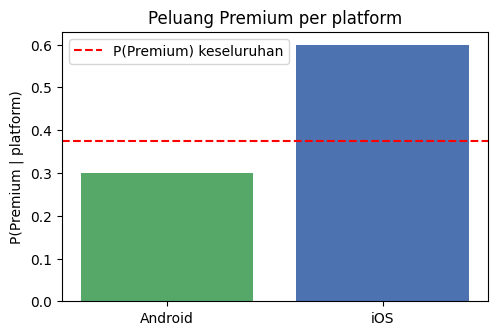

In [8]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.DataFrame({"Premium": [45, 30], "Gratis": [105, 20]}, index=["Android", "iOS"])
total = df.values.sum()
print(df, "\nTotal pengguna =", total)

P_premium = df["Premium"].sum() / total
P_ios = df.loc["iOS"].sum() / total
P_ios_premium = df.loc["iOS", "Premium"] / total
P_prem_ios = P_ios_premium / P_ios
P_prem_android = df.loc["Android", "Premium"] / df.loc["Android"].sum()
P_ios_prem = P_ios_premium / P_premium

print("\nP(Premium)          =", round(P_premium, 4))
print("P(iOS)              =", round(P_ios, 4))
print("P(Premium | iOS)    =", round(P_prem_ios, 4))
print("P(Premium | Android) =", round(P_prem_android, 4))
print("P(iOS | Premium)    =", round(P_ios_prem, 4))

# Uji independensi: independen jika P(iOS dan Premium) = P(iOS) x P(Premium)
print("\nP(iOS) x P(Premium)  =", round(P_ios * P_premium, 5), "| P(iOS dan Premium) =", P_ios_premium)
chi2, p_value, dof, _ = stats.chi2_contingency(df.values)
print("Uji chi-square: chi2 =", round(chi2, 3), "| p-value =", round(p_value, 5))

rasio = df["Premium"] / df.sum(axis=1)
plt.figure(figsize=(5.5, 3.5))
plt.bar(rasio.index, rasio.values, color=["#55A868", "#4C72B0"])
plt.axhline(P_premium, color="red", ls="--", label="P(Premium) keseluruhan")
plt.ylabel("P(Premium | platform)"); plt.title("Peluang Premium per platform"); plt.legend(); plt.show()

P(ditandai)         = 0.299
P(spam | ditandai)  = 0.9532
P(spam | ditandai 2 filter) = 0.999
Simulasi P(spam | ditandai) = 0.9537


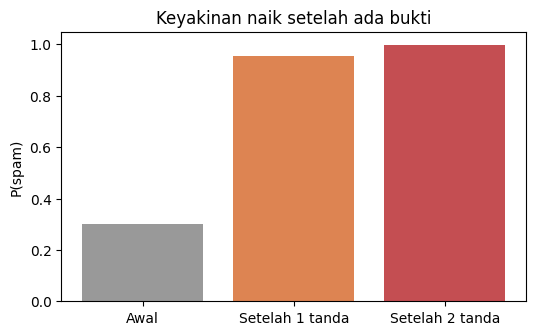

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

p_spam, sens, fpr = 0.30, 0.95, 0.02      # P(Spam), P(ditandai|Spam), P(ditandai|bukan Spam)

# Hukum probabilitas total: peluang sebuah email ditandai filter
p_tandai = sens * p_spam + fpr * (1 - p_spam)
# Teorema Bayes
p_spam_tandai = sens * p_spam / p_tandai
print("P(ditandai)         =", round(p_tandai, 4))
print("P(spam | ditandai)  =", round(p_spam_tandai, 4))

# Bukti kedua: filter kedua (independen) juga menandai
prior2 = p_spam_tandai
p_tandai2 = sens * prior2 + fpr * (1 - prior2)
p_spam_tandai2 = sens * prior2 / p_tandai2
print("P(spam | ditandai 2 filter) =", round(p_spam_tandai2, 4))

# Simulasi 1.000.000 email
N = 1_000_000
spam = rng.random(N) < p_spam
ditandai = np.where(spam, rng.random(N) < sens, rng.random(N) < fpr)
print("Simulasi P(spam | ditandai) =", round(spam[ditandai].mean(), 4))

plt.figure(figsize=(6, 3.5))
plt.bar(["Awal", "Setelah 1 tanda", "Setelah 2 tanda"], [p_spam, p_spam_tandai, p_spam_tandai2],
        color=["#999999", "#DD8452", "#C44E52"])
plt.ylabel("P(spam)"); plt.title("Keyakinan naik setelah ada bukti"); plt.show()

n = 23 -> P = 0.5073
Jumlah orang minimal agar P >= 50% : 23
Simulasi n = 23 -> 0.514


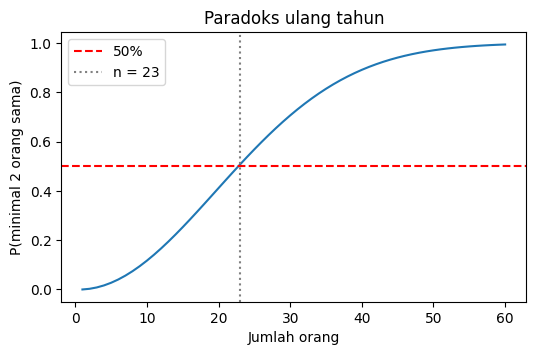

In [10]:
import math
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

def peluang_sama(n):
    """P(minimal dua orang berulang tahun sama) di antara n orang"""
    peluang_beda = math.prod((365 - i) / 365 for i in range(n))
    return 1 - peluang_beda

print("n = 23 -> P =", round(peluang_sama(23), 4))
n_min = next(n for n in range(1, 366) if peluang_sama(n) >= 0.5)
print("Jumlah orang minimal agar P >= 50% :", n_min)

# Simulasi: 20.000 kelompok berisi 23 orang
N = 20_000
sama = sum(len(set(rng.integers(0, 365, 23))) < 23 for _ in range(N))
p_sim = sama / N
print("Simulasi n = 23 ->", round(p_sim, 4))

n = np.arange(1, 61)
plt.figure(figsize=(6, 3.5))
plt.plot(n, [peluang_sama(i) for i in n])
plt.axhline(0.5, color="red", ls="--", label="50%")
plt.axvline(23, color="gray", ls=":", label="n = 23")
plt.xlabel("Jumlah orang"); plt.ylabel("P(minimal 2 orang sama)")
plt.title("Paradoks ulang tahun"); plt.legend(); plt.show()

n =     10 | rata-rata = 3.2000 | SD rata-rata = 0.5401
n =    100 | rata-rata = 3.1300 | SD rata-rata = 0.1708
n =   1000 | rata-rata = 3.4830 | SD rata-rata = 0.0540
n =  10000 | rata-rata = 3.5000 | SD rata-rata = 0.0171


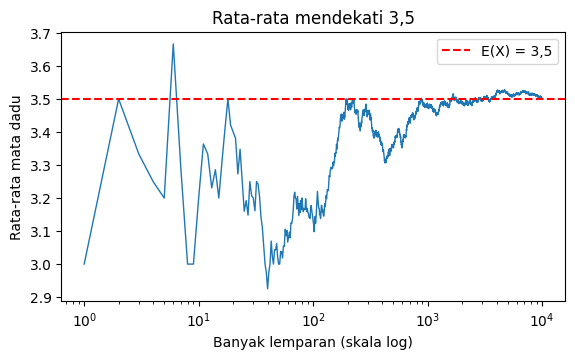

In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

teori = np.mean(np.arange(1, 7))                 # nilai harapan = 3,5
N = 10_000
lempar = rng.integers(1, 7, size=N)              # 10.000 lemparan dadu
rata_kum = np.cumsum(lempar) / np.arange(1, N + 1)

for n in [10, 100, 1000, 10000]:
    sd = math.sqrt((35 / 12) / n)
    print(f"n = {n:6d} | rata-rata = {rata_kum[n-1]:.4f} | SD rata-rata = {sd:.4f}")

plt.figure(figsize=(6.5, 3.5))
plt.plot(np.arange(1, N + 1), rata_kum, lw=1)
plt.axhline(3.5, color="red", ls="--", label="E(X) = 3,5")
plt.xscale("log"); plt.xlabel("Banyak lemparan (skala log)"); plt.ylabel("Rata-rata mata dadu")
plt.title("Rata-rata mendekati 3,5"); plt.legend(); plt.show()

P(klik)        = 0.12
P(tidak klik) = 0.88
E(X) = 0.12 | Var(X) = 0.1056
Simulasi: rata-rata = 0.1205 | varians = 0.106


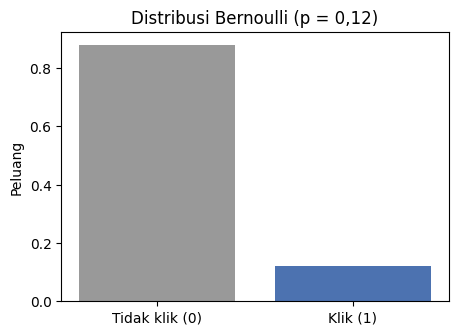

In [12]:
from scipy import stats
import matplotlib.pyplot as plt

p = 0.12                                    # peluang pengguna mengklik iklan
X = stats.bernoulli(p)
print("P(klik)        =", X.pmf(1))
print("P(tidak klik) =", round(X.pmf(0), 2))
print("E(X) =", round(X.mean(), 4), "| Var(X) =", round(X.var(), 4))

data = X.rvs(100_000, random_state=1)
print("Simulasi: rata-rata =", round(data.mean(), 4), "| varians =", round(data.var(), 4))

plt.figure(figsize=(5, 3.5))
plt.bar(["Tidak klik (0)", "Klik (1)"], X.pmf([0, 1]), color=["#999999", "#4C72B0"])
plt.ylabel("Peluang"); plt.title("Distribusi Bernoulli (p = 0,12)"); plt.show()

P(X = 14) = 0.3658
P(X >= 13) = 0.9638
P(X = 15) = 0.4633
E(X) = 14.25 | Var(X) = 0.7125
Simulasi: P(X = 14) = 0.3642 | rata-rata = 14.2511


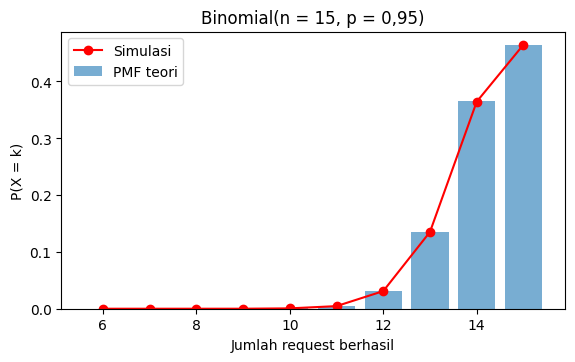

In [13]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

n, p = 15, 0.95
X = stats.binom(n, p)
print("P(X = 14) =", round(X.pmf(14), 4))
print("P(X >= 13) =", round(X.sf(12), 4))          # sf(12) = P(X > 12)
print("P(X = 15) =", round(X.pmf(15), 4))
print("E(X) =", X.mean(), "| Var(X) =", round(X.var(), 4))

data = X.rvs(100_000, random_state=2)
print("Simulasi: P(X = 14) =", round(np.mean(data == 14), 4), "| rata-rata =", round(data.mean(), 4))

k = np.arange(6, 16)
plt.figure(figsize=(6.5, 3.6))
plt.bar(k, X.pmf(k), alpha=0.6, label="PMF teori")
plt.plot(k, [np.mean(data == i) for i in k], "ro-", label="Simulasi")
plt.xlabel("Jumlah request berhasil"); plt.ylabel("P(X = k)")
plt.title("Binomial(n = 15, p = 0,95)"); plt.legend(); plt.show()

P(X = 6) = 0.1042
P(X >= 8) = 0.0511
P(X <= 2) = 0.2381
E(X) = 4.0 | Var(X) = 4.0
P(0 tiket dalam 30 menit) = 0.1353
Simulasi: P(X = 6) = 0.1037 | rata-rata = 4.0002


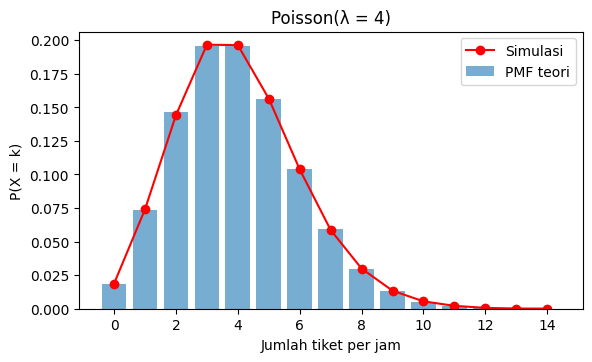

In [14]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

lam = 4                                    # rata-rata 4 tiket per jam
X = stats.poisson(lam)
print("P(X = 6) =", round(X.pmf(6), 4))
print("P(X >= 8) =", round(X.sf(7), 4))
print("P(X <= 2) =", round(X.cdf(2), 4))
print("E(X) =", X.mean(), "| Var(X) =", X.var())

# Ubah satuan waktu: 30 menit -> lambda = 2
print("P(0 tiket dalam 30 menit) =", round(stats.poisson(2).pmf(0), 4))

data = X.rvs(100_000, random_state=3)
print("Simulasi: P(X = 6) =", round(np.mean(data == 6), 4), "| rata-rata =", round(data.mean(), 4))

k = np.arange(0, 15)
plt.figure(figsize=(6.5, 3.6))
plt.bar(k, X.pmf(k), alpha=0.6, label="PMF teori")
plt.plot(k, [np.mean(data == i) for i in k], "ro-", label="Simulasi")
plt.xlabel("Jumlah tiket per jam"); plt.ylabel("P(X = k)")
plt.title("Poisson(λ = 4)"); plt.legend(); plt.show()

P(X = 3) = 0.144
P(X <= 3) = 0.784
E(X) = 2.5 | Var(X) = 3.75
Simulasi: rata-rata = 2.5044 | varians = 3.7826


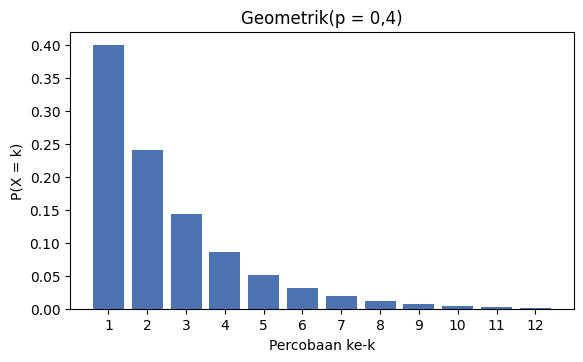

In [15]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

p = 0.4
G = stats.geom(p)                          # X = percobaan ke-berapa sukses pertama (mulai dari 1)
print("P(X = 3) =", round(G.pmf(3), 4))
print("P(X <= 3) =", round(G.cdf(3), 4))
print("E(X) =", round(G.mean(), 4), "| Var(X) =", round(G.var(), 4))

data = G.rvs(100_000, random_state=4)
print("Simulasi: rata-rata =", round(data.mean(), 4), "| varians =", round(data.var(), 4))

k = np.arange(1, 13)
plt.figure(figsize=(6.5, 3.6))
plt.bar(k, G.pmf(k), color="#4C72B0")
plt.xlabel("Percobaan ke-k"); plt.ylabel("P(X = k)")
plt.title("Geometrik(p = 0,4)"); plt.xticks(k); plt.show()

P(sukses ke-3 tepat di percobaan ke-6) = 0.13824
P(selesai dalam <= 6 percobaan)        = 0.45568
E(percobaan) = 7.499999999999999 | Var = 11.25
Simulasi: rata-rata percobaan = 7.497 | varians = 11.2732


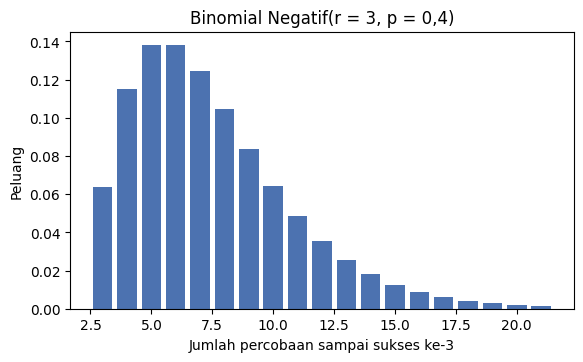

In [16]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

r, p = 3, 0.4                              # butuh 3 sukses, peluang sukses tiap percobaan 0,4
NB = stats.nbinom(r, p)                    # di SciPy: X = jumlah GAGAL sebelum sukses ke-r
gagal = 3                                  # sukses ke-3 di percobaan ke-6 -> ada 3 gagal
print("P(sukses ke-3 tepat di percobaan ke-6) =", round(NB.pmf(gagal), 5))
print("P(selesai dalam <= 6 percobaan)        =", round(NB.cdf(gagal), 5))
rata_percobaan = NB.mean() + r             # percobaan = gagal + sukses
print("E(percobaan) =", rata_percobaan, "| Var =", round(NB.var(), 4))

data = NB.rvs(100_000, random_state=5) + r
print("Simulasi: rata-rata percobaan =", round(data.mean(), 4), "| varians =", round(data.var(), 4))

n = np.arange(3, 22)
plt.figure(figsize=(6.5, 3.6))
plt.bar(n, NB.pmf(n - r), color="#4C72B0")
plt.xlabel("Jumlah percobaan sampai sukses ke-3"); plt.ylabel("Peluang")
plt.title("Binomial Negatif(r = 3, p = 0,4)"); plt.show()

P(X = 0) = 0.2983
P(X = 1) = 0.4474
P(X >= 1) = 0.7017
E(X) = 1.0 | Var(X) = 0.6897
Jika dianggap binomial: P(X >= 1) = 0.6723


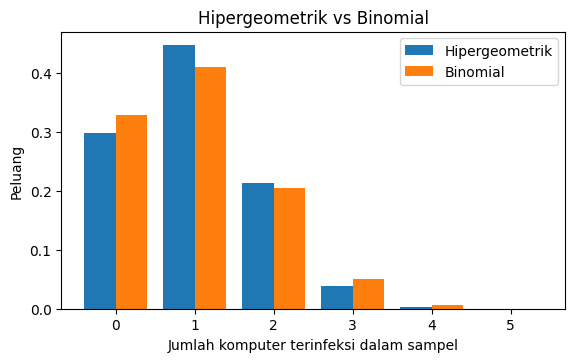

In [17]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

N_total, K_malware, n_ambil = 30, 6, 5
H = stats.hypergeom(N_total, K_malware, n_ambil)    # urutan: populasi, jumlah "sukses", ukuran sampel
print("P(X = 0) =", round(H.pmf(0), 4))
print("P(X = 1) =", round(H.pmf(1), 4))
print("P(X >= 1) =", round(H.sf(0), 4))
print("E(X) =", H.mean(), "| Var(X) =", round(H.var(), 4))

B = stats.binom(n_ambil, K_malware / N_total)        # bila dianggap dengan pengembalian
print("Jika dianggap binomial: P(X >= 1) =", round(B.sf(0), 4))

k = np.arange(0, 6)
plt.figure(figsize=(6.5, 3.6))
plt.bar(k - 0.2, H.pmf(k), width=0.4, label="Hipergeometrik")
plt.bar(k + 0.2, B.pmf(k), width=0.4, label="Binomial")
plt.xlabel("Jumlah komputer terinfeksi dalam sampel"); plt.ylabel("Peluang")
plt.title("Hipergeometrik vs Binomial"); plt.legend(); plt.show()

E(X) = 1.2 | E(X^2) = 2.8
Var(X) = 1.36 | SD = 1.1662
Harapan biaya perbaikan = Rp 1.8 juta per sprint
SciPy: mean = 1.2 | var = 1.36
Simulasi: rata-rata = 1.1931


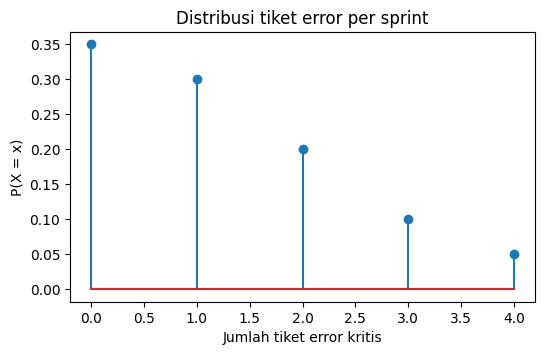

In [18]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

x = np.array([0, 1, 2, 3, 4])
p = np.array([0.35, 0.30, 0.20, 0.10, 0.05])
assert np.isclose(p.sum(), 1)                     # total peluang harus 1

E = np.sum(x * p)
E2 = np.sum(x ** 2 * p)
Var = E2 - E ** 2
print("E(X) =", round(E, 4), "| E(X^2) =", round(E2, 4))
print("Var(X) =", round(Var, 4), "| SD =", round(np.sqrt(Var), 4))
print("Harapan biaya perbaikan = Rp", round(1.5 * E, 2), "juta per sprint")

D = stats.rv_discrete(values=(x, p))               # cek dengan SciPy
print("SciPy: mean =", round(D.mean(), 4), "| var =", round(D.var(), 4))
data = D.rvs(size=100_000, random_state=10)
print("Simulasi: rata-rata =", round(data.mean(), 4))

plt.figure(figsize=(6, 3.5))
plt.stem(x, p); plt.xlabel("Jumlah tiket error kritis"); plt.ylabel("P(X = x)")
plt.title("Distribusi tiket error per sprint"); plt.show()

P(20 < X < 35) = 0.375
P(X > 45)      = 0.125
E(X) = 30.0 | Var(X) = 133.3333
Simulasi P(20 < X < 35) = 0.3747


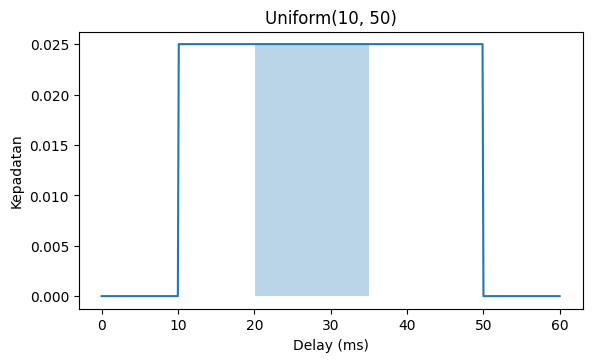

In [19]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

a, b = 10, 50
U = stats.uniform(loc=a, scale=b - a)             # SciPy: loc = awal, scale = lebar
p_20_35 = U.cdf(35) - U.cdf(20)
print("P(20 < X < 35) =", round(p_20_35, 4))
print("P(X > 45)      =", round(U.sf(45), 4))
print("E(X) =", U.mean(), "| Var(X) =", round(U.var(), 4))

data = U.rvs(100_000, random_state=6)
print("Simulasi P(20 < X < 35) =", round(np.mean((data > 20) & (data < 35)), 4))

x = np.linspace(0, 60, 500)
plt.figure(figsize=(6.5, 3.6))
plt.plot(x, U.pdf(x))
plt.fill_between(x, U.pdf(x), where=(x >= 20) & (x <= 35), alpha=0.3)
plt.xlabel("Delay (ms)"); plt.ylabel("Kepadatan"); plt.title("Uniform(10, 50)"); plt.show()

lambda = 0.125
P(X > 10) = 0.2865
P(X <= 5) = 0.4647
Median   = 5.5452 menit
E(X) = 8.0 | Var(X) = 64.0
P(X > 15 | X > 5) = 0.2865
Simulasi P(X > 10) = 0.2878


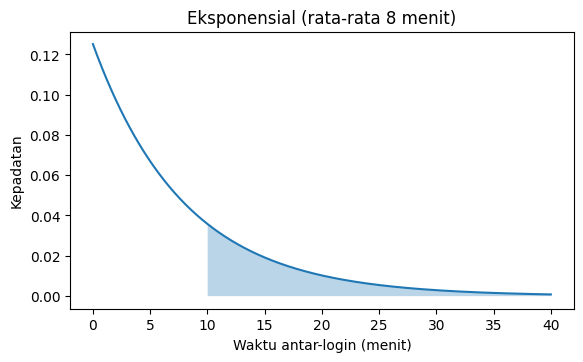

In [20]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rata = 8                                  # rata-rata 8 menit antar-login
E = stats.expon(scale=rata)               # scale = 1/lambda = rata-rata
print("lambda =", 1 / rata)
print("P(X > 10) =", round(E.sf(10), 4))
print("P(X <= 5) =", round(E.cdf(5), 4))
print("Median   =", round(E.median(), 4), "menit")
print("E(X) =", E.mean(), "| Var(X) =", E.var())

# Sifat tanpa ingatan: P(X > 15 | X > 5) = P(X > 10)
print("P(X > 15 | X > 5) =", round(E.sf(15) / E.sf(5), 4))

data = E.rvs(100_000, random_state=7)
print("Simulasi P(X > 10) =", round(np.mean(data > 10), 4))

x = np.linspace(0, 40, 500)
plt.figure(figsize=(6.5, 3.6))
plt.plot(x, E.pdf(x))
plt.fill_between(x, E.pdf(x), where=(x >= 10), alpha=0.3)
plt.xlabel("Waktu antar-login (menit)"); plt.ylabel("Kepadatan")
plt.title("Eksponensial (rata-rata 8 menit)"); plt.show()

P(X <= 5) = 0.427
E(X) = 6.0 | Var(X) = 9.0
Simulasi: rata-rata = 6.0023 | P(X <= 5) = 0.4266


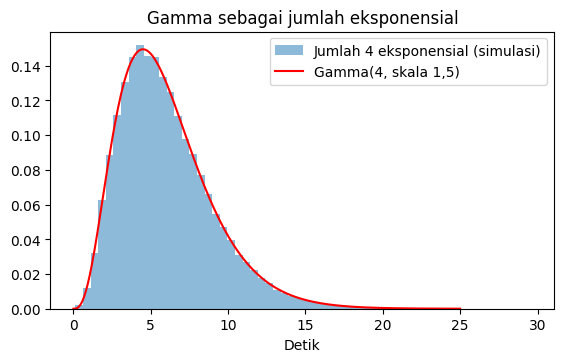

In [21]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

k_req, rata_antar = 4, 1.5                # 4 request, antar-kedatangan ~ Eksponensial(rata-rata 1,5 detik)
Gm = stats.gamma(a=k_req, scale=rata_antar)
print("P(X <= 5) =", round(Gm.cdf(5), 4))
print("E(X) =", Gm.mean(), "| Var(X) =", Gm.var())

# Verifikasi: jumlah 4 variabel eksponensial
jumlah = stats.expon(scale=rata_antar).rvs((100_000, k_req), random_state=9).sum(axis=1)
print("Simulasi: rata-rata =", round(jumlah.mean(), 4), "| P(X <= 5) =", round(np.mean(jumlah <= 5), 4))

x = np.linspace(0, 25, 400)
plt.figure(figsize=(6.5, 3.6))
plt.hist(jumlah, bins=60, density=True, alpha=0.5, label="Jumlah 4 eksponensial (simulasi)")
plt.plot(x, Gm.pdf(x), "r-", label="Gamma(4, skala 1,5)")
plt.xlabel("Detik"); plt.legend(); plt.title("Gamma sebagai jumlah eksponensial"); plt.show()

P(X > 3)          = 0.1151
P(1,9 < X < 2,9) = 0.6827
Persentil ke-95  = 3.2224 detik
z untuk X = 3     = 1.2
E(X) = 2.4 | Var(X) = 0.25
Simulasi P(X > 3) = 0.1154


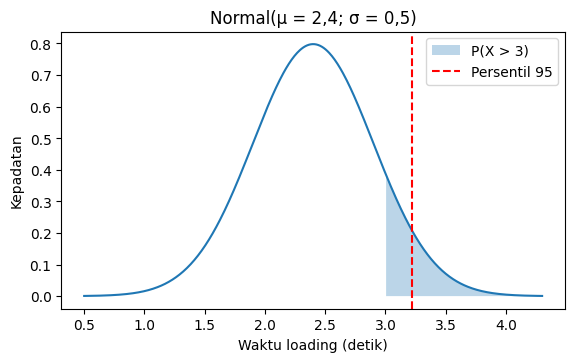

In [22]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

mu, sigma = 2.4, 0.5
W = stats.norm(mu, sigma)
print("P(X > 3)          =", round(W.sf(3), 4))
print("P(1,9 < X < 2,9) =", round(W.cdf(2.9) - W.cdf(1.9), 4))
print("Persentil ke-95  =", round(W.ppf(0.95), 4), "detik")
print("z untuk X = 3     =", round((3 - mu) / sigma, 2))
print("E(X) =", W.mean(), "| Var(X) =", W.var())

data = W.rvs(100_000, random_state=8)
print("Simulasi P(X > 3) =", round(np.mean(data > 3), 4))

x = np.linspace(0.5, 4.3, 500)
plt.figure(figsize=(6.5, 3.6))
plt.plot(x, W.pdf(x))
plt.fill_between(x, W.pdf(x), where=(x >= 3), alpha=0.3, label="P(X > 3)")
plt.axvline(W.ppf(0.95), color="red", ls="--", label="Persentil 95")
plt.xlabel("Waktu loading (detik)"); plt.ylabel("Kepadatan")
plt.title("Normal(μ = 2,4; σ = 0,5)"); plt.legend(); plt.show()

Mean = 30.0 | SD = 4.5826
P(X <= 35) eksak binomial    = 0.8839
Hampiran normal (35,5)      = 0.885
Hampiran normal tanpa koreksi = 0.8624
Rata-rata dari rata-rata: 3.4991 | SD simulasi: 0.3123 | SD teori: 0.3118


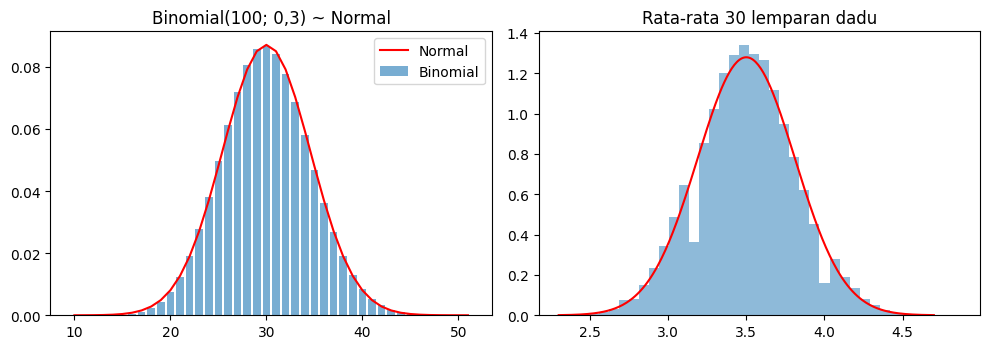

In [23]:
import math
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng()

n, p = 100, 0.3
B = stats.binom(n, p)
mu, sd = n * p, math.sqrt(n * p * (1 - p))
print("Mean =", mu, "| SD =", round(sd, 4))

eksak = B.cdf(35)
hampiran = stats.norm(mu, sd).cdf(35.5)             # koreksi kontinuitas: 35 -> 35,5
tanpa_koreksi = stats.norm(mu, sd).cdf(35)
print("P(X <= 35) eksak binomial    =", round(eksak, 4))
print("Hampiran normal (35,5)      =", round(hampiran, 4))
print("Hampiran normal tanpa koreksi =", round(tanpa_koreksi, 4))

# Teorema Limit Pusat: rata-rata 30 lemparan dadu, diulang 20.000 kali
rata = rng.integers(1, 7, size=(20_000, 30)).mean(axis=1)
sd_teori = math.sqrt((35 / 12) / 30)
print("Rata-rata dari rata-rata:", round(rata.mean(), 4), "| SD simulasi:", round(rata.std(), 4),
      "| SD teori:", round(sd_teori, 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
k = np.arange(10, 52)
ax[0].bar(k, B.pmf(k), alpha=0.6, label="Binomial")
ax[0].plot(k, stats.norm(mu, sd).pdf(k), "r-", label="Normal")
ax[0].set_title("Binomial(100; 0,3) ~ Normal"); ax[0].legend()

x = np.linspace(2.3, 4.7, 300)
ax[1].hist(rata, bins=40, density=True, alpha=0.5)
ax[1].plot(x, stats.norm(3.5, sd_teori).pdf(x), "r-")
ax[1].set_title("Rata-rata 30 lemparan dadu")
plt.tight_layout(); plt.show()

Chi-square hitung (manual) = 5.96
Derajat bebas              = 4
Nilai kritis (alpha 0,05)  = 9.4877
SciPy: statistik = 5.96 | p-value = 0.2022
Keputusan: H0 tidak ditolak


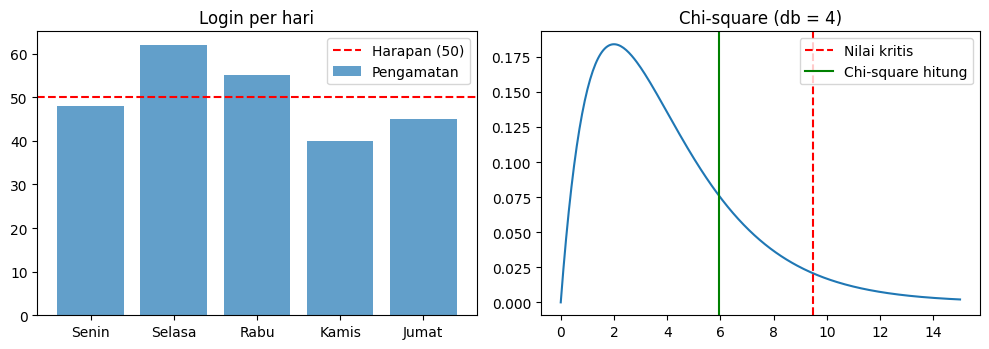

In [24]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat"]
observasi = np.array([48, 62, 55, 40, 45])             # login per hari
harapan = np.full(5, observasi.sum() / 5)              # jika merata: 50 per hari

chi_hitung = np.sum((observasi - harapan) ** 2 / harapan)
db = len(observasi) - 1
kritis = stats.chi2.ppf(0.95, db)
uji = stats.chisquare(observasi, harapan)

print("Chi-square hitung (manual) =", round(chi_hitung, 4))
print("Derajat bebas              =", db)
print("Nilai kritis (alpha 0,05)  =", round(kritis, 4))
print("SciPy: statistik =", round(uji.statistic, 4), "| p-value =", round(uji.pvalue, 4))
print("Keputusan:", "tolak H0" if chi_hitung > kritis else "H0 tidak ditolak")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(hari, observasi, alpha=0.7, label="Pengamatan")
ax[0].axhline(50, color="red", ls="--", label="Harapan (50)")
ax[0].set_title("Login per hari"); ax[0].legend()

x = np.linspace(0, 15, 300)
ax[1].plot(x, stats.chi2(db).pdf(x))
ax[1].axvline(kritis, color="red", ls="--", label="Nilai kritis")
ax[1].axvline(chi_hitung, color="green", label="Chi-square hitung")
ax[1].set_title("Chi-square (db = 4)"); ax[1].legend()
plt.tight_layout(); plt.show()